# Longtail Point: prolonged low-water component

**Magnitude:** 175.90-176.30 m, inclusive, on the **trailing 12-month mean**. **Duration:** 24-60 consecutive monthly timesteps, inclusive. Each maximal uninterrupted occurrence of final component success is counted once.

This notebook focuses on the standard magnitude + duration component, consistently across all scenarios. The previously computed baseline result is **37 component events in 1,030 years = 3.59 events per 100 years**. This is not the earlier whole-parent/seasonality-screened subset. No extra depth or seasonal-amplitude screen is applied.

The `_0_0` scenario supplies baseline diagnostics. Dates span **1970-2999**, so this scenario record should not be interpreted as historical observations. Levels are interpreted as metres; CSV supplies no vertical datum or model provenance. Statistical component success does not establish species benefits.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from climate_canvas.plots_utilities import plot_response_surface
from IPython.display import display
from matplotlib.colors import Normalize

from hydropattern.parsers import duration_parser, magnitude_parser
from hydropattern.patterns import Component, find_runs, moving_average
from hydropattern.scenario_grid import build_grid, parse_scenario_name
from hydropattern.scenarios import evaluate_scenarios
from hydropattern.timeseries import Timeseries

In [2]:
example = Path.cwd()
if not (example / 'michiganhuron_avg.csv').is_file():
    example = next(
        root / 'examples' / 'longtailpoint'
        for root in (Path.cwd(), *Path.cwd().parents)
        if (root / 'examples' / 'longtailpoint' / 'michiganhuron_avg.csv').is_file()
    )
data = example / 'michiganhuron_avg.csv'
ts = Timeseries.from_csv(str(data), date_format='%Y-%m-%d')
scenario_names = list(ts.data.columns[:-1])
assert ts.data.index.is_unique and ts.data.index.is_monotonic_increasing
assert np.all(np.diff(ts.data.index.to_period('M').asi8) == 1)
assert np.isfinite(ts.data[scenario_names].to_numpy()).all()
assert ts.data.groupby(ts.data.index.year).size().eq(12).all()
baseline = ts.data['_0_0']
exposure_years = len(baseline) / 12
LOWER_M, UPPER_M = 175.90, 176.30
MEAN_MONTHS = 12
MIN_MONTHS, MAX_MONTHS = 24, 60
mean12 = pd.Series(
    moving_average(baseline.to_numpy(), MEAN_MONTHS), index=baseline.index
)
assert np.allclose(
    mean12, baseline.rolling(MEAN_MONTHS, min_periods=MEAN_MONTHS).mean(),
    rtol=0, atol=1e-12, equal_nan=True,
)
print(f'{len(baseline):,} monthly observations; {exposure_years:,.0f} years; '
      f'{len(scenario_names)} scenarios.')
display(ts.data[scenario_names].head())

12,360 monthly observations; 1,030 years; 17 scenarios.


,_0_0,_0_1.5,_0_3,_0_5,_0_7,_5_1.5,_5_3,_5_5,_5_7,_10_3,_10_5,_10_7,_15_3,_15_5,_15_7,_20_5,_20_7
time,,,,,,,,,,,,,,,,,
1970-01-01,176.63,176.19,175.78,175.22,174.60,176.70,176.30,175.78,175.18,176.73,176.23,175.66,177.25,176.76,176.21,177.33,176.81
1970-02-01,176.63,176.19,175.78,175.24,174.61,176.71,176.32,175.80,175.21,176.75,176.25,175.68,177.26,176.78,176.24,177.36,176.85
1970-03-01,176.67,176.25,175.83,175.29,174.67,176.76,176.37,175.86,175.27,176.81,176.32,175.75,177.33,176.85,176.31,177.44,176.93
1970-04-01,176.76,176.34,175.92,175.38,174.76,176.87,176.46,175.95,175.37,176.92,176.42,175.86,177.44,176.96,176.42,177.57,177.07
1970-05-01,176.82,176.38,175.95,175.41,174.81,176.91,176.50,175.99,175.41,176.96,176.47,175.91,177.48,177.00,176.47,177.63,177.13


## Why this magnitude band?

Baseline trailing-mean **1st percentile is about 175.892 m** and **25th percentile about 176.292 m**. Rounded to 0.10 m, they give 175.90 and 176.30 m. This is a transparent lower-tail definition, not a threshold optimized to achieve an expected recurrence interval. Keep thresholds fixed across scenarios.

The band applies to annual-scale **means**, not individual monthly levels. Normal annual variation need not fit inside its 0.40 m width. Baseline annual monthly max-minus-min range has **median 0.32 m**, with central 90% approximately **0.20-0.52 m**. These describe variability; they are not additional component conditions.

Trailing smoothing removes recurring seasonal swings and shifts apparent spell timing relative to a centred annual mean. First 11 means are unavailable, not filled or classified as failures. Duration is assessed on an entire maximal band-qualified run: a 61-month run fails; it is not divided into qualifying 24-60-month windows.

,Monthly level (m),Trailing 12-month mean (m),Annual monthly range (m)
Quantile,,,
0.01,175.82,175.8921,0.15
0.05,175.99,176.0428,0.20
0.25,176.28,176.2917,0.27
0.50,176.52,176.5175,0.32
0.75,176.76,176.7500,0.39
0.95,177.08,177.0497,0.52
0.99,177.35,177.3267,0.60


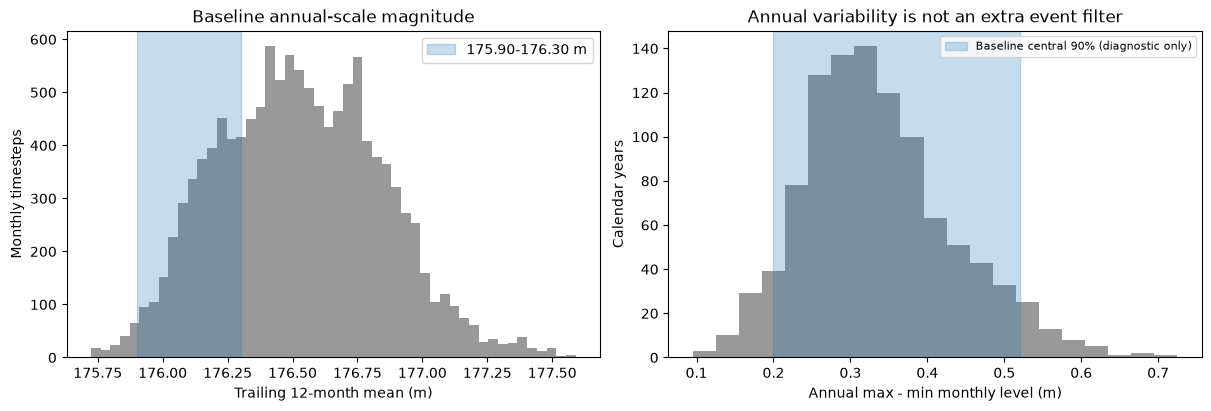

In [3]:
annual = baseline.groupby(baseline.index.year).agg(['mean', 'min', 'max'])
annual['range_m'] = (annual['max'] - annual['min']).round(2)
quantiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
quantile_table = pd.DataFrame({
    'Monthly level (m)': baseline.quantile(quantiles),
    'Trailing 12-month mean (m)': mean12.quantile(quantiles),
    'Annual monthly range (m)': annual['range_m'].quantile(quantiles),
})
quantile_table.index.name = 'Quantile'
display(quantile_table.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].hist(mean12.dropna(), bins=50, color='0.6')
axes[0].axvspan(LOWER_M, UPPER_M, color='tab:blue', alpha=0.25,
               label='175.90-176.30 m')
axes[0].set(xlabel='Trailing 12-month mean (m)', ylabel='Monthly timesteps',
            title='Baseline annual-scale magnitude')
axes[0].legend()
season_low, season_high = annual['range_m'].quantile([0.05, 0.95])
axes[1].hist(annual['range_m'], bins=np.arange(0.095, 0.746, 0.03), color='0.6')
axes[1].axvspan(season_low, season_high, color='tab:blue', alpha=0.25,
               label='Baseline central 90% (diagnostic only)')
axes[1].set(xlabel='Annual max - min monthly level (m)', ylabel='Calendar years',
            title='Annual variability is not an extra event filter')
axes[1].legend(fontsize=8)
plt.show()

In [4]:
low_cycle = Component(
    name='low_water_cycle',
    characteristics=[
        magnitude_parser(metrics=[LOWER_M, UPPER_M, MEAN_MONTHS], order=1),
        duration_parser(metrics=[MIN_MONTHS, MAX_MONTHS], order=2),
    ],
    is_success_pattern=True,
)
scenario_results = evaluate_scenarios(ts, [low_cycle])
component_results = scenario_results.by_component(low_cycle.name)
baseline_result = component_results['_0_0']
assert baseline_result.event_count() == 37
assert np.isclose(baseline_result.event_rate() * 100, 37 / exposure_years * 100)
print(f'Baseline: {baseline_result.event_count()} events in {exposure_years:.0f} years '
      f'= {baseline_result.event_rate() * 100:.2f} events per 100 years.')

Baseline: 37 events in 1030 years = 3.59 events per 100 years.


## Baseline component events and interpretation

**Frequency = 100 x component event count / observed exposure in years.** On this complete monthly record exposure is observations / 12. This counts distinct final component-success runs, not qualifying months or overlapping windows; it does not imply evenly spaced episodes.

A lower-bound crossing can split a longer physical low-water episode into several band-qualified runs. The selected component intentionally uses this ordinary band-only behavior. The event table identifies each run's larger **parent spell below 176.30 m** so those fragments remain visible. It does not silently reject them. A whole-parent rejection rule would be a different component.

Normal seasonal amplitude and ecological benefits remain diagnostic questions, not implicit success conditions. The final response surface uses the same component definition for every scenario.

The time-series figure shows the first **1,000 years (1970-2969)** in five stacked **200-year** panels with a shared level scale. The separate histogram and all event-rate calculations retain the full **1,030-year** record.

,Start,End,Months,Minimum 12-month mean (m),Maximum 12-month mean (m),Complete years,Median annual range (m),Parent low months,Fragment of parent low
0,1976-06,1980-10,53,176.047,176.296,3,0.340,53,False
1,1991-03,1994-07,41,175.986,176.299,2,0.445,41,False
2,2048-04,2050-07,28,176.054,176.299,1,0.360,28,False
3,2072-01,2075-02,38,175.994,176.298,3,0.230,38,False
4,2083-04,2086-04,37,176.061,176.298,2,0.395,37,False
5,2107-12,2110-03,28,175.902,176.297,2,0.270,86,True
6,2110-05,2115-01,57,175.901,176.271,4,0.320,86,True
7,2126-03,2129-11,45,175.958,176.298,2,0.370,45,False
8,2139-04,2142-05,38,175.938,176.292,2,0.435,38,False
9,2157-08,2160-06,35,176.193,176.298,2,0.290,35,False


Median event length: 38.0 months; 11 events are parent-low fragments.


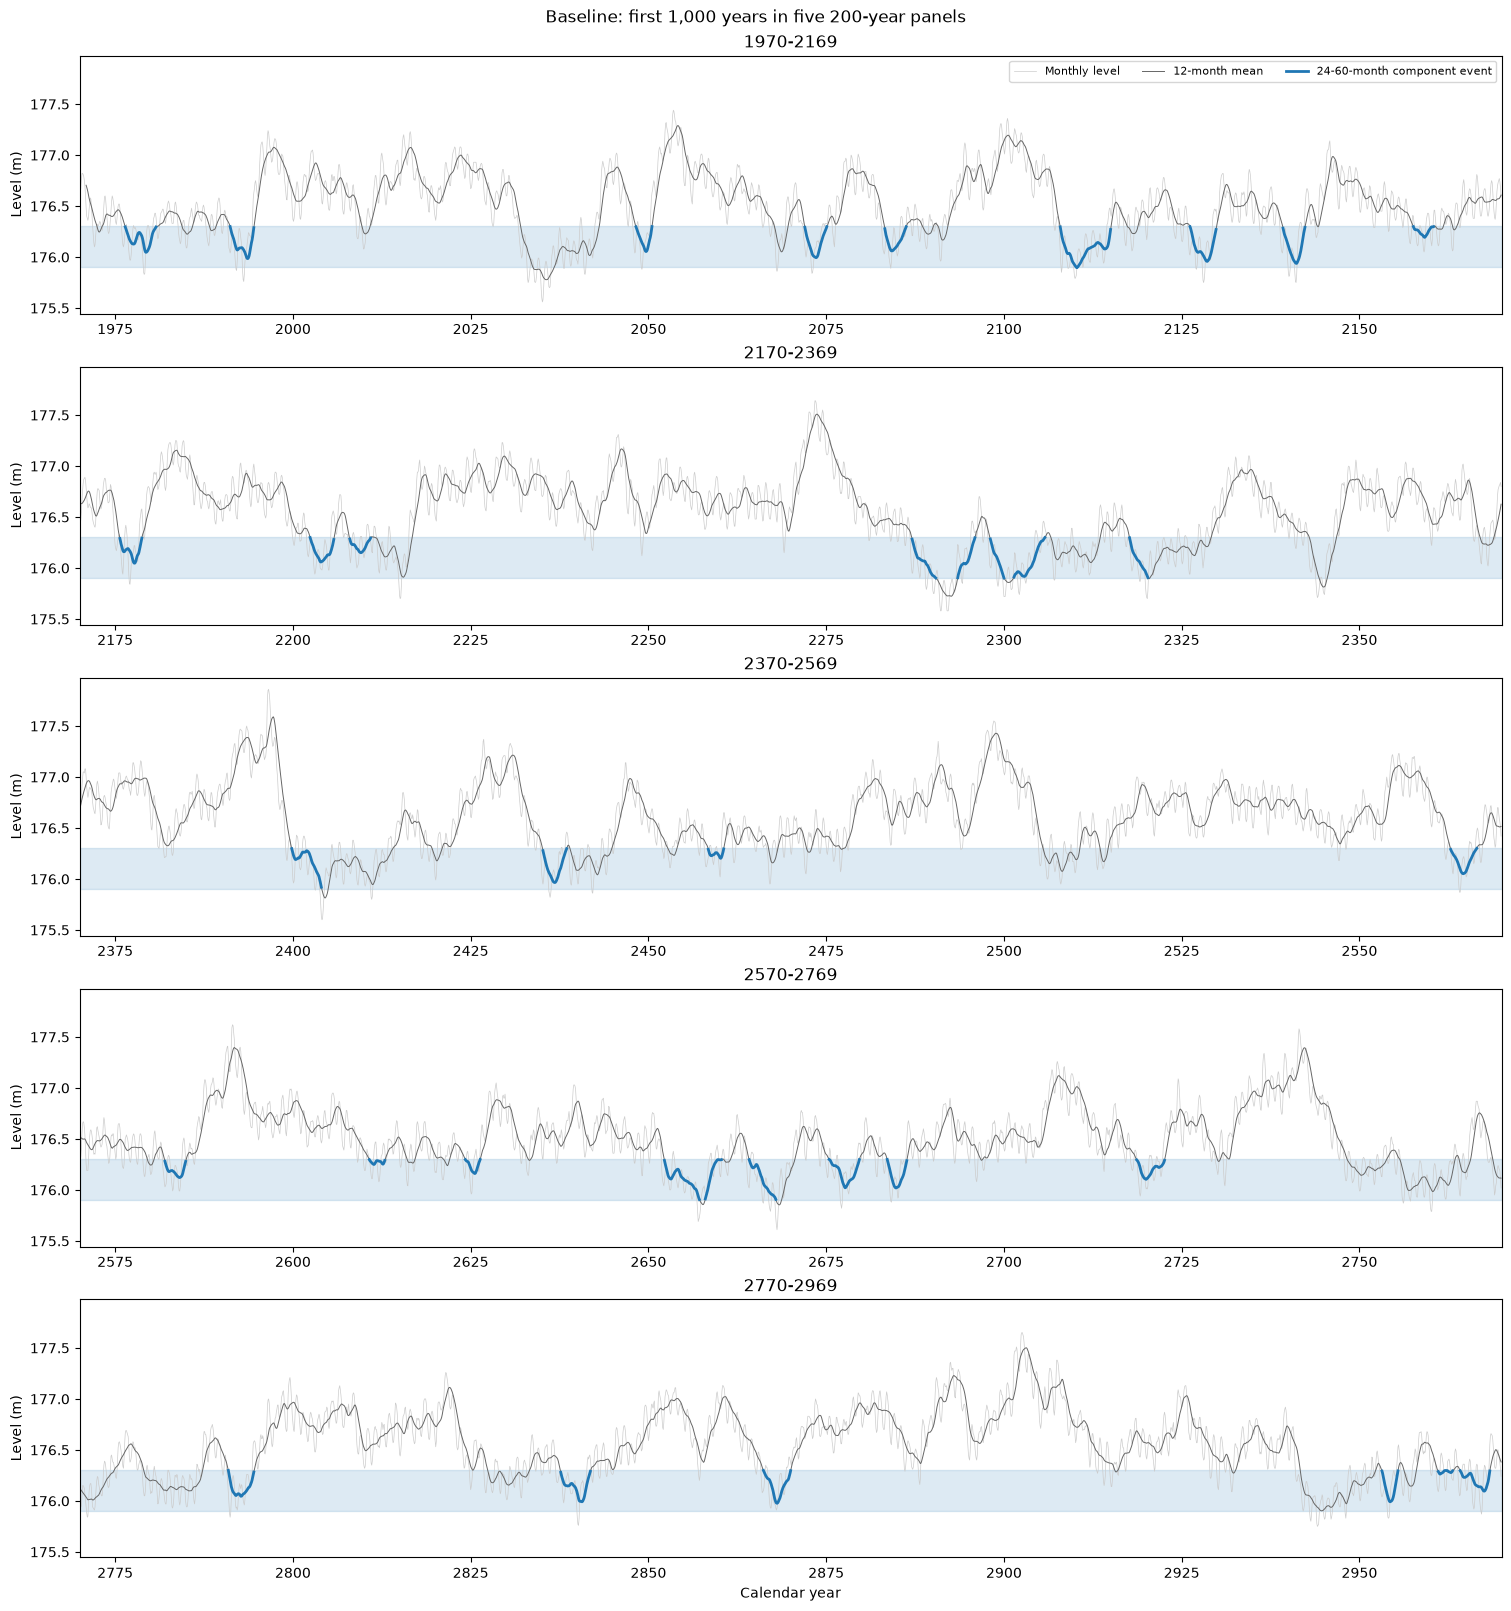

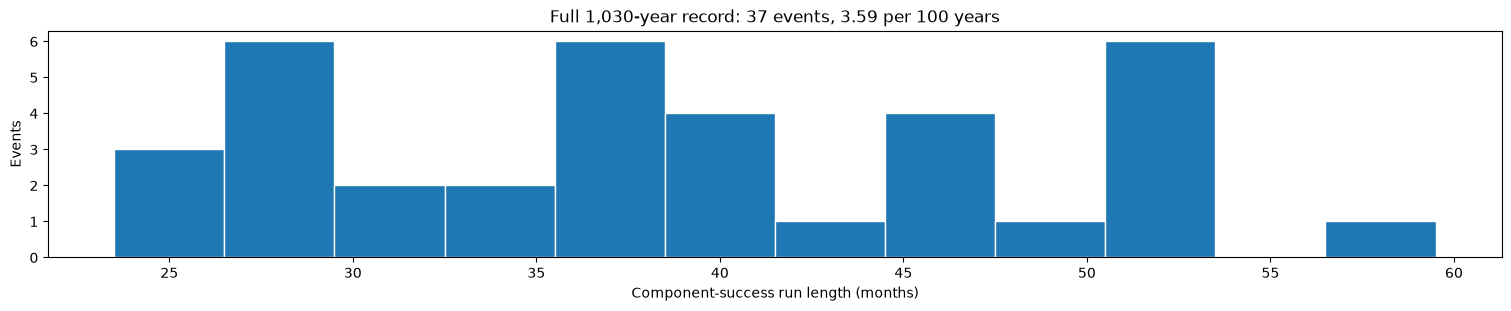

In [5]:
success_runs = find_runs(baseline_result.df[low_cycle.name].to_numpy())
parent_runs = find_runs(mean12.le(UPPER_M).to_numpy(dtype=float))
event_rows = []
for start, end in success_runs:
    parent_start, parent_end = next(
        (first, last) for first, last in parent_runs if first <= start and end <= last
    )
    raw = baseline.iloc[start:end + 1]
    year_counts = raw.groupby(raw.index.year).size()
    full_years = year_counts.index[year_counts.eq(12)]
    amplitudes = annual.loc[full_years, 'range_m']
    event_rows.append({
        'Start': baseline.index[start].strftime('%Y-%m'),
        'End': baseline.index[end].strftime('%Y-%m'),
        'Months': end - start + 1,
        'Minimum 12-month mean (m)': mean12.iloc[start:end + 1].min(),
        'Maximum 12-month mean (m)': mean12.iloc[start:end + 1].max(),
        'Complete years': len(full_years),
        'Median annual range (m)': amplitudes.median(),
        'Parent low months': parent_end - parent_start + 1,
        'Fragment of parent low': (start, end) != (parent_start, parent_end),
    })
baseline_events = pd.DataFrame(event_rows)
assert len(baseline_events) == baseline_result.event_count()
assert baseline_events['Months'].between(MIN_MONTHS, MAX_MONTHS).all()
assert baseline_events['Minimum 12-month mean (m)'].ge(LOWER_M).all()
assert baseline_events['Maximum 12-month mean (m)'].le(UPPER_M).all()
display(baseline_events.round(3))
print(f"Median event length: {baseline_events['Months'].median():.1f} months; "
      f"{baseline_events['Fragment of parent low'].sum()} events are parent-low fragments.")
panel_months = 200 * 12
plot_months = 5 * panel_months
assert len(baseline) >= plot_months, 'Plot requires 1,000 complete years.'
plot_years = baseline.index.year + (baseline.index.month - 1) / 12
event_means = mean12.where(baseline_result.df[low_cycle.name].eq(1))
fig, axes = plt.subplots(5, 1, figsize=(15, 16), sharey=True,
                         constrained_layout=True)
for panel, ax in enumerate(axes):
    first = panel * panel_months
    last = first + panel_months
    years = plot_years[first:last]
    ax.plot(years, baseline.iloc[first:last], color='0.8', linewidth=0.5,
            label='Monthly level')
    ax.plot(years, mean12.iloc[first:last], color='0.4', linewidth=0.7,
            label='12-month mean')
    ax.plot(years, event_means.iloc[first:last], color='tab:blue', linewidth=2,
            label='24-60-month component event')
    ax.axhspan(LOWER_M, UPPER_M, color='tab:blue', alpha=0.15)
    start_year = int(baseline.index[first].year)
    ax.set(xlim=(start_year, start_year + 200), ylabel='Level (m)',
           title=f'{start_year}-{start_year + 199}')
    ax.ticklabel_format(axis='x', useOffset=False)
axes[0].legend(fontsize=8, ncols=3)
axes[-1].set_xlabel('Calendar year')
fig.suptitle('Baseline: first 1,000 years in five 200-year panels')
plt.show()
fig, ax = plt.subplots(figsize=(15, 3), constrained_layout=True)
ax.hist(baseline_events['Months'], bins=np.arange(23.5, 61.5, 3),
        color='tab:blue', edgecolor='white')
ax.set(xlabel='Component-success run length (months)', ylabel='Events',
       title='Full 1,030-year record: 37 events, 3.59 per 100 years')
plt.show()

## Scenario event rates

Use `Result.event_count_bounds()` and `Result.event_rate_bounds()` for each scenario. Equal bounds identify an exact count/rate; multiply events per year by 100. Zero events is a valid zero, not missing data.

Unknown outcomes can leave event counts ambiguous even with high known-outcome coverage. Tables disclose count/rate bounds and unknown timesteps. At the user's request, `_0_1.5` is plotted using the **midpoint of its computed rate bounds**; other ambiguous rates remain blank. The table labels this choice explicitly. This is **not a minimum-coverage filter**. Missing scenario combinations also remain blank.

The surfaces below plot **events per 100 years**, not portion of known outcomes. Precipitation delta is horizontal; temperature delta is vertical. Colors describe occurrence rate only, not ecological benefit. Both use the plotting library's default **RdBu** color map with the same scale.

**Value for (0% precipitation, +1.5 deg C):** scenario `_0_1.5` has **27 unknown outcome timesteps**, with event-count bounds **59-73** and rate bounds **5.73-7.09 events per 100 years**. Its displayed midpoint is **6.41 events per 100 years** (66 / 1,030 x 100). This is a descriptive representative value, not an exact count or a statistically estimated expected rate. The code calculates the midpoint from unrounded bounds, retaining uncertainty in the table.

**First figure:** `interpolate=False, fillin=False` displays evaluated rates plus the explicitly chosen `_0_1.5` midpoint. **Second figure:** `interpolate=True, fillin=True` estimates remaining gaps using those supplied rates. Both receive the same 6.41 value at `_0_1.5`; it is no longer spatially filled. Outlined input cells include this midpoint, so outlines do not imply every value is exact. Filling is for visual comparison, not a replacement for the bounds table.

In [6]:
scenario_rows = []
for name, result in component_results.items():
    coordinates = parse_scenario_name(name)
    if coordinates is None:
        raise ValueError(f'Invalid scenario-grid name: {name}')
    precipitation_delta, temperature_delta = coordinates
    counts = result.event_count_bounds()
    rates = result.event_rate_bounds()
    exact = counts.lower == counts.upper and rates.lower == rates.upper
    plotted_rate = rates.lower * 100 if exact else np.nan
    rate_basis = 'Exact' if exact else 'Ambiguous; not plotted'
    if name == '_0_1.5' and not exact:
        plotted_rate = (rates.lower + rates.upper) / 2 * 100
        rate_basis = 'Midpoint of bounds (user-selected)'
    scenario_rows.append({
        'Scenario': name,
        'Precipitation delta (%)': precipitation_delta,
        'Temperature delta (deg C)': temperature_delta,
        'Exposure (years)': len(result.df) / 12,
        'Event count lower': counts.lower,
        'Event count upper': counts.upper,
        'Events per 100 years lower': rates.lower * 100,
        'Events per 100 years upper': rates.upper * 100,
        'Events per 100 years': plotted_rate,
        'Plotted rate basis': rate_basis,
        'Unknown outcome timesteps': int(result.df[low_cycle.name].isna().sum()),
    })
scenario_rates = pd.DataFrame(scenario_rows).set_index('Scenario')
display(scenario_rates.round(3))
ambiguous = scenario_rates.index[scenario_rates['Events per 100 years'].isna()].tolist()
if ambiguous:
    print('Ambiguous event rates left blank in surface:', ', '.join(ambiguous))
assert np.isclose(scenario_rates.loc['_0_0', 'Events per 100 years'], 37 / 1030 * 100)
midpoint_row = scenario_rates.loc['_0_1.5']
assert np.isclose(
    midpoint_row['Events per 100 years'],
    (midpoint_row['Events per 100 years lower']
     + midpoint_row['Events per 100 years upper']) / 2,
)
precipitation_deltas, temperature_deltas, event_rate_grid = build_grid(
    list(component_results), scenario_rates['Events per 100 years'].to_dict()
)
display(pd.DataFrame(
    event_rate_grid,
    index=pd.Index(temperature_deltas, name='Temperature delta (deg C)'),
    columns=pd.Index(precipitation_deltas, name='Precipitation delta (%)'),
).round(3))

,Precipitation delta (%),Temperature delta (deg C),Exposure (years),Event count lower,Event count upper,Events per 100 years lower,Events per 100 years upper,Events per 100 years,Plotted rate basis,Unknown outcome timesteps
Scenario,,,,,,,,,,
_0_0,0.0,0.0,1030.0,37,37,3.592,3.592,3.592,Exact,0
_0_1.5,0.0,1.5,1030.0,59,73,5.728,7.087,6.408,Midpoint of bounds (user-selected),27
_0_3,0.0,3.0,1030.0,27,27,2.621,2.621,2.621,Exact,0
_0_5,0.0,5.0,1030.0,1,1,0.097,0.097,0.097,Exact,0
_0_7,0.0,7.0,1030.0,0,0,0.000,0.000,0.000,Exact,0
_5_1.5,5.0,1.5,1030.0,34,34,3.301,3.301,3.301,Exact,0
_5_3,5.0,3.0,1030.0,67,67,6.505,6.505,6.505,Exact,0
_5_5,5.0,5.0,1030.0,25,25,2.427,2.427,2.427,Exact,0
_5_7,5.0,7.0,1030.0,1,1,0.097,0.097,0.097,Exact,0


Precipitation delta (%),0.0,5.0,10.0,15.0,20.0
Temperature delta (deg C),,,,,
0.0,3.592,NaN,NaN,NaN,NaN
1.5,6.408,3.301,NaN,NaN,NaN
3.0,2.621,6.505,3.301,0.097,NaN
5.0,0.097,2.427,5.825,3.495,0.097
7.0,0.000,0.097,1.553,5.049,3.107


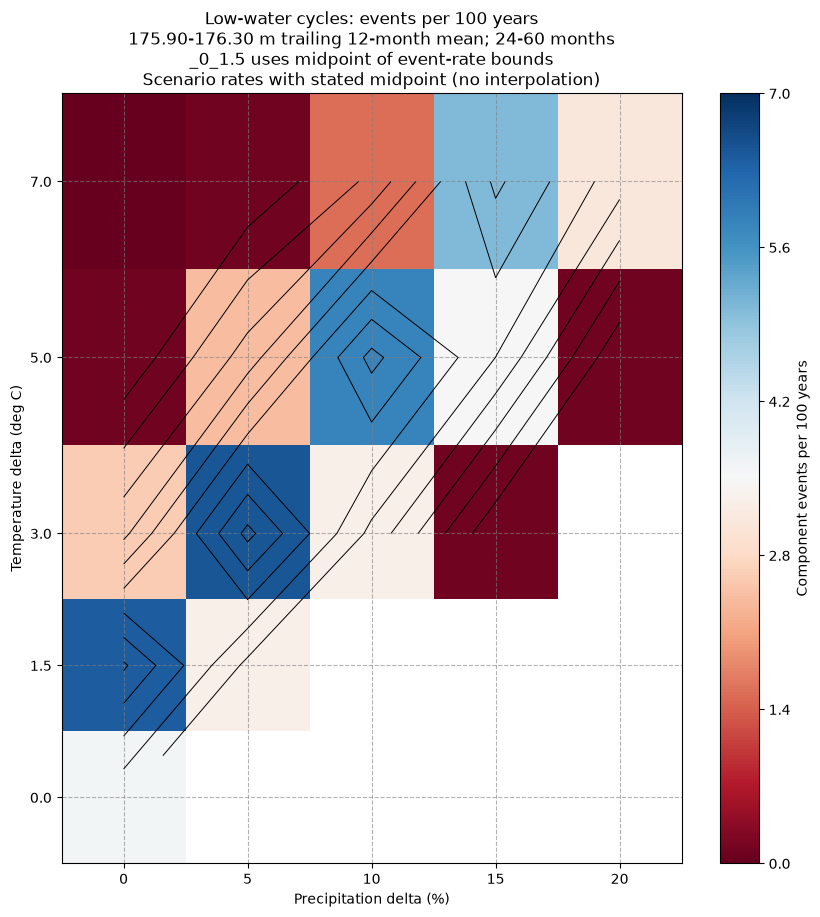

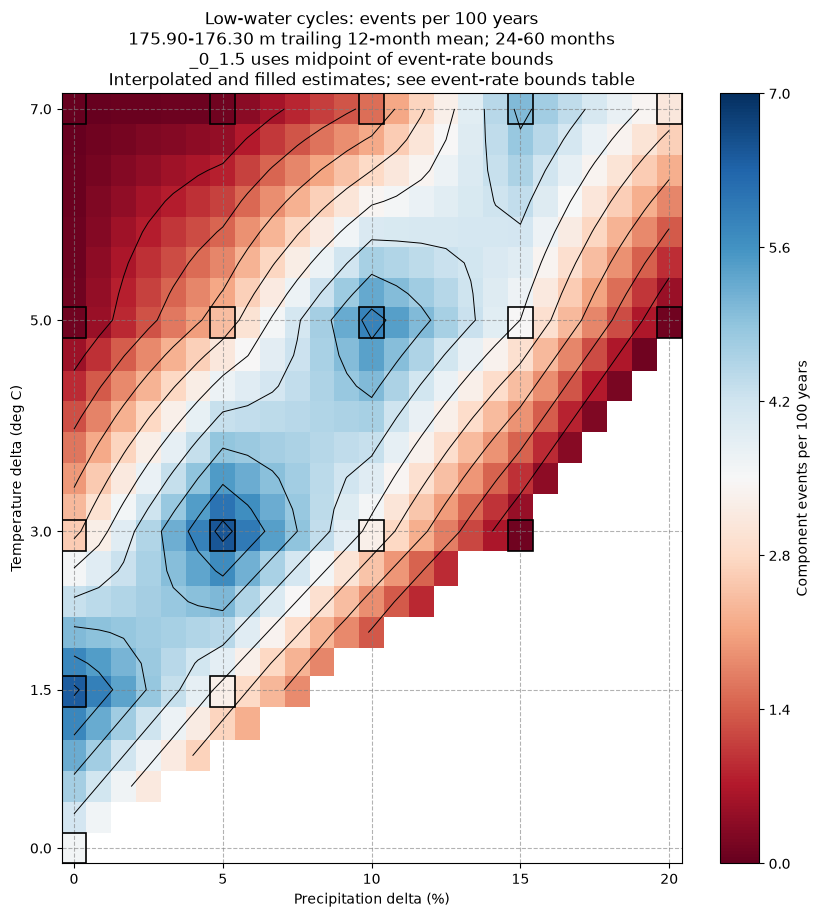

In [7]:
finite_points = np.argwhere(np.isfinite(event_rate_grid))
if len(finite_points) < 3 or np.linalg.matrix_rank(
    finite_points[1:] - finite_points[0]
) < 2:
    raise ValueError('At least three non-collinear supplied scenario rates are needed.')
maximum_rate = float(np.nanmax(event_rate_grid))
scale_max = max(1.0, np.ceil(maximum_rate))
color_ticks = np.linspace(0, scale_max, 6).tolist()
contour_levels = tuple(np.linspace(0, scale_max, 11))
surface_title = 'Low-water cycles: events per 100 years\n'
surface_title += '175.90-176.30 m trailing 12-month mean; 24-60 months'
surface_title += '\n_0_1.5 uses midpoint of event-rate bounds'
assert 'coverage' not in surface_title.lower()
for interpolate, fillin, subtitle in [
    (False, False, 'Scenario rates with stated midpoint (no interpolation)'),
    (True, True, 'Interpolated and filled estimates; see event-rate bounds table'),
]:
    plot_response_surface(
        precipitation_deltas, temperature_deltas, event_rate_grid.copy(),
        interpolate=interpolate, fillin=fillin,
        labels=('Precipitation delta (%)', 'Temperature delta (deg C)',
                'Component events per 100 years'),
        title=f'{surface_title}\n{subtitle}',
        color_map_ticks=color_ticks,
        norm=Normalize(vmin=0, vmax=scale_max),
        levels=contour_levels,
        widths=tuple(0.7 for _ in contour_levels),
        show=True,
    )